# **USMAN_RASHEED_TRN_2026_000313**

In [ ]:
# ------------------------------------------------------------
# CELL 1: Check Python + PyTorch + device.
# ------------------------------------------------------------
import sys                                  # To read interpreter version.
print("Python:", sys.version.split()[0])    # Print "3.x.y".

import torch                                # PyTorch core (tensors, autograd, layers).
print("PyTorch:", torch.__version__)        # Confirm torch imported correctly.

# Choose GPU if Colab provides one, otherwise CPU.
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print("Device:", device)                    # Prints 'cuda' or 'cpu'.

Python: 3.13.16
PyTorch: 2.14.1+cu130
Device: cuda


In [ ]:
# ------------------------------------------------------------
# CELL 2: Fix seeds, load digits, scale pixels to 0-1.
# ------------------------------------------------------------
import random                                        # Python RNG.
import numpy as np                                   # Numeric arrays.

SEED = 42                                            # Any int.
torch.manual_seed(SEED)                              # Fix PyTorch randomness (weights, shuffles).
np.random.seed(SEED)                                 # Fix NumPy randomness (used by sklearn internals).
random.seed(SEED)                                    # Fix Python randomness.

from sklearn.datasets import load_digits             # 1797 handwritten 8x8 images, labels 0-9.
digits = load_digits()                               # Load once.

X_images = digits.images.astype(np.float32)          # Shape (1797, 8, 8). Values are ints 0-16.
y_labels = digits.target.astype(np.int64)            # Shape (1797,), values 0-9.

X_images = X_images / 16.0                           # NORMALIZE: 0-16 -> 0-1 (rubric scale example).

print("X shape:", X_images.shape)                    # (1797, 8, 8).
print("y shape:", y_labels.shape)                    # (1797,).
print("Pixel range:", X_images.min(), "->", X_images.max())   # 0.0 -> 1.0.
print("Class counts:", np.bincount(y_labels))        # Each digit appears ~178 times.

X shape: (1797, 8, 8)
y shape: (1797,)
Pixel range: 0.0 -> 1.0
Class counts: [178 182 177 183 181 182 181 179 174 180]


In [ ]:
# ------------------------------------------------------------
# CELL 3: Stratified train/valid/test split — same arrays for CNN and ViT.
# ------------------------------------------------------------
from sklearn.model_selection import train_test_split

# Step 1: reserve 40% (validation + test together).
X_tr, X_hold, y_tr, y_hold = train_test_split(
    X_images, y_labels,
    test_size=0.40,                                  # 40% held out.
    random_state=SEED,                               # Reproducible.
    stratify=y_labels                                # Keep class balance.
)

# Step 2: split the 40% in half -> 20% valid, 20% test.
X_va, X_te, y_va, y_te = train_test_split(
    X_hold, y_hold,
    test_size=0.50,                                  # Half of 40% = 20% of total.
    random_state=SEED,
    stratify=y_hold                                  # Stratify again.
)

print("Train:", X_tr.shape, "Valid:", X_va.shape, "Test:", X_te.shape)
# Expect ~ (1078,8,8) (359,8,8) (360,8,8).

Train: (1078, 8, 8) Valid: (359, 8, 8) Test: (360, 8, 8)


In [ ]:
# ------------------------------------------------------------
# CELL 4: Wrap tensors for batching.
# ------------------------------------------------------------
from torch.utils.data import TensorDataset, DataLoader

def to_cnn_tensor(arr):
    # arr shape (N,8,8) -> (N,1,8,8): add a channel dim for Conv2d.
    return torch.from_numpy(arr).float().unsqueeze(1)

Xtr = to_cnn_tensor(X_tr)                    # [N,1,8,8].
Xva = to_cnn_tensor(X_va)
Xte = to_cnn_tensor(X_te)

ytr = torch.from_numpy(y_tr).long()          # CrossEntropyLoss expects int64 labels.
yva = torch.from_numpy(y_va).long()
yte = torch.from_numpy(y_te).long()

print("Train tensor:", Xtr.shape, ytr.shape) # [~1078,1,8,8] [~1078].

# DataLoaders: 32 images per batch, shuffle train only.
train_loader = DataLoader(TensorDataset(Xtr, ytr), batch_size=32, shuffle=True,  num_workers=0)
valid_loader = DataLoader(TensorDataset(Xva, yva), batch_size=32, shuffle=False, num_workers=0)
test_loader  = DataLoader(TensorDataset(Xte, yte), batch_size=32, shuffle=False, num_workers=0)

xb, yb = next(iter(train_loader))            # First batch.
print("One batch:", xb.shape, yb.shape)      # [32,1,8,8] [32].

Train tensor: torch.Size([1078, 1, 8, 8]) torch.Size([1078])
One batch: torch.Size([32, 1, 8, 8]) torch.Size([32])


In [ ]:
# ------------------------------------------------------------
# CELL 5: Small CNN for 8x8 single-channel images -> 10 logits.
# ------------------------------------------------------------
from torch import nn

class DigitCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(1, 16, 3, padding=1)   # 1 in-channel -> 16 filters, 3x3 kernel, keep 8x8.
        self.conv2 = nn.Conv2d(16, 32, 3, padding=1)  # 16 -> 32 filters.
        self.act   = nn.ReLU()                        # ReLU(max(0,x)) after each conv.
        self.pool  = nn.MaxPool2d(2)                  # Downsample by 2 (8->4->2).
        self.fc1   = nn.Linear(32 * 2 * 2, 64)        # Flattened 128 -> 64 hidden.
        self.fc2   = nn.Linear(64, 10)                # 64 -> 10 class logits.

    def forward(self, x):                             # x: [N,1,8,8]
        x = self.act(self.conv1(x))                   # [N,16,8,8]
        x = self.pool(x)                              # [N,16,4,4]
        x = self.act(self.conv2(x))                   # [N,32,4,4]
        x = self.pool(x)                              # [N,32,2,2]
        x = x.flatten(1)                              # [N,128]
        x = self.act(self.fc1(x))                     # [N,64]
        return self.fc2(x)                            # [N,10] raw scores

cnn = DigitCNN().to(device)
out = cnn(torch.randn(2, 1, 8, 8).to(device))         # Shape check.
print("CNN output:", out.shape)                       # [2,10].

CNN output: torch.Size([2, 10])


In [ ]:
# ------------------------------------------------------------
# CELL 6: Turn each 8x8 image into 16 patches of 2x2 = 4 values each.
# ------------------------------------------------------------
def patchify(x):
    """
    x: [N,1,8,8] float tensor.
    Returns: [N,16,4] — 16 patches per image, 4 pixel values per patch.
    """
    # view: [N,1,8,8] -> [N,1,4,2,4,2]. Splits H into 4 groups of 2, W into 4 groups of 2.
    p = x.view(-1, 1, 4, 2, 4, 2)
    # permute to arrange each 2x2 pixel block contiguously: [N,1,4,4,2,2].
    p = p.permute(0, 1, 2, 4, 3, 5)
    # reshape to [N,16,4]: 4*4=16 patches, 2*2=4 values each.
    return p.reshape(-1, 16, 4)

demo = Xtr[:2]                                        # Two real images.
p = patchify(demo)
print("Patches:", p.shape)                            # [2,16,4].
# Reverse check: patches -> image.
restored = p.reshape(2, 4, 4, 2, 2).permute(0,1,3,2,4).reshape(2, 8, 8)
print("Round-trip equal:", torch.allclose(restored, demo.squeeze(1)))   # True.

Patches: torch.Size([2, 16, 4])
Round-trip equal: True


In [ ]:
# ------------------------------------------------------------
# CELL 7: Minimal ViT — patch embed + positions + attention + head.
# ------------------------------------------------------------
class DigitViT(nn.Module):
    def __init__(self, embed_dim=32, n_heads=4, n_layers=2, dropout=0.1):
        super().__init__()
        # Trainable patch projection: 4 pixels -> 32-dim embedding.
        self.patch_proj = nn.Linear(4, embed_dim)
        # Learnable positional embedding: one vector per of 16 slots.
        self.pos_embed  = nn.Parameter(torch.zeros(1, 16, embed_dim))
        # One TransformerEncoderLayer = self-attention + FFN + residual + norm.
        encoder_layer = nn.TransformerEncoderLayer(
            d_model=embed_dim,             # Must match embedding size.
            nhead=n_heads,                 # 4 attention heads.
            dim_feedforward=64,            # Feed-forward inner width.
            dropout=dropout,
            batch_first=True,              # Input shape [N, seq, dim].
        )
        self.encoder = nn.TransformerEncoder(encoder_layer, num_layers=n_layers)
        self.norm    = nn.LayerNorm(embed_dim)      # Normalize after encoding.
        self.head    = nn.Linear(embed_dim, 10)     # 10-class classifier.

    def forward(self, x):                           # x: [N,1,8,8]
        tokens = self.patch_proj(patchify(x))       # [N,16,32] (patch projection).
        tokens = tokens + self.pos_embed            # Add positional info (broadcast).
        tokens = self.encoder(tokens)               # Attention across 16 tokens.
        tokens = self.norm(tokens)                  # LayerNorm.
        pooled = tokens.mean(dim=1)                 # Average pool over 16 tokens.
        return self.head(pooled)                    # [N,10] logits.

vit = DigitViT().to(device)
print("ViT output:", vit(torch.randn(2,1,8,8).to(device)).shape)   # [2,10].

ViT output: torch.Size([2, 10])


In [ ]:
# ------------------------------------------------------------
# CELL 8: One training loop used for both CNN and ViT.
# ------------------------------------------------------------
def train_model(model, train_loader, valid_loader, epochs=15, lr=1e-3):
    loss_fn   = nn.CrossEntropyLoss()                    # Multi-class loss (works on logits).
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)   # Adam optimizer.

    best_acc = 0.0
    best_state = None

    for epoch in range(1, epochs + 1):
        model.train()                                    # Training mode (dropout active).
        running = 0.0
        for xb, yb in train_loader:
            xb, yb = xb.to(device), yb.to(device)        # Same device as model.
            optimizer.zero_grad()                        # Clear previous gradients.
            logits = model(xb)                           # Forward pass -> [N,10].
            loss   = loss_fn(logits, yb)                 # Compute loss.
            loss.backward()                              # Backprop.
            optimizer.step()                             # Update weights.
            running += loss.item() * len(xb)             # Weighted by batch size.
        train_loss = running / len(train_loader.dataset)

        # Validation.
        model.eval()                                     # Disable dropout.
        correct = total = 0
        with torch.no_grad():                            # No gradients needed.
            for xb, yb in valid_loader:
                xb, yb = xb.to(device), yb.to(device)
                preds = model(xb).argmax(dim=1)          # Predicted class per row.
                correct += (preds == yb).sum().item()
                total   += len(yb)
        acc = correct / total

        if acc > best_acc:                               # Checkpoint best (rubric 7).
            best_acc   = acc
            best_state = {k: v.clone() for k, v in model.state_dict().items()}

        if epoch % 3 == 0 or epoch == 1:
            print(f"  epoch {epoch:2d} | train {train_loss:.4f} | valid acc {acc:.4f}")

    model.load_state_dict(best_state)                    # Restore best weights.
    return best_acc

# ---- Train both models on the SAME loaders ----
print("Training CNN…")
cnn_acc = train_model(cnn, train_loader, valid_loader, epochs=15, lr=1e-3)
print(f"CNN best valid acc: {cnn_acc:.4f}")

print("\nTraining ViT…")
vit_acc = train_model(vit, train_loader, valid_loader, epochs=20, lr=1e-3)
print(f"ViT best valid acc: {vit_acc:.4f}")

Training CNN…
  epoch  1 | train 2.2800 | valid acc 0.3287
  epoch  3 | train 1.4920 | valid acc 0.8078
  epoch  6 | train 0.3893 | valid acc 0.9025
  epoch  9 | train 0.2044 | valid acc 0.9192
  epoch 12 | train 0.1307 | valid acc 0.9471
  epoch 15 | train 0.0865 | valid acc 0.9526
CNN best valid acc: 0.9526

Training ViT…
  epoch  1 | train 2.3197 | valid acc 0.1003
  epoch  3 | train 2.1565 | valid acc 0.2702
  epoch  6 | train 1.0861 | valid acc 0.7577
  epoch  9 | train 0.5328 | valid acc 0.8496
  epoch 12 | train 0.2858 | valid acc 0.8914
  epoch 15 | train 0.1883 | valid acc 0.9248
  epoch 18 | train 0.1320 | valid acc 0.9331
ViT best valid acc: 0.9331


Model    Accuracy    MacroF1
----------------------------
Base       0.1028          —
CNN        0.9444     0.9445
ViT        0.9278     0.9279


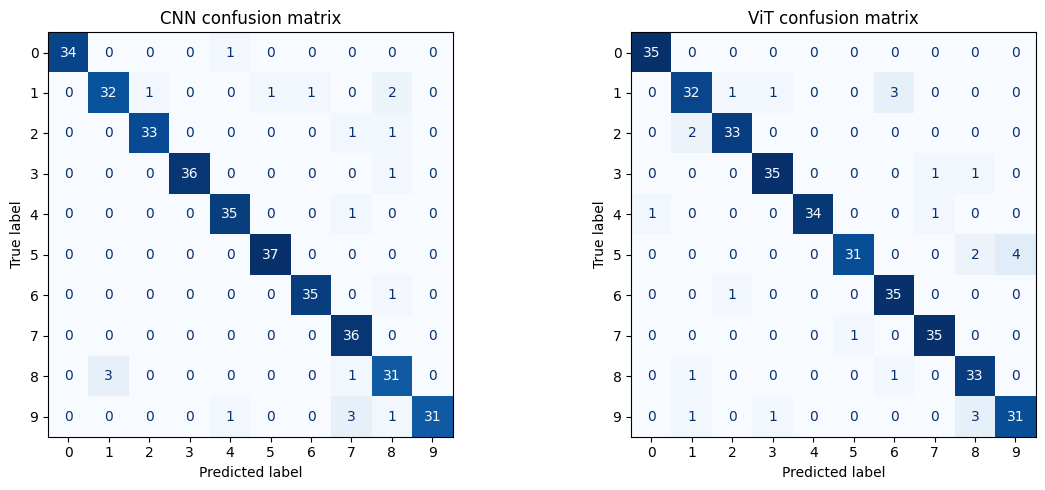

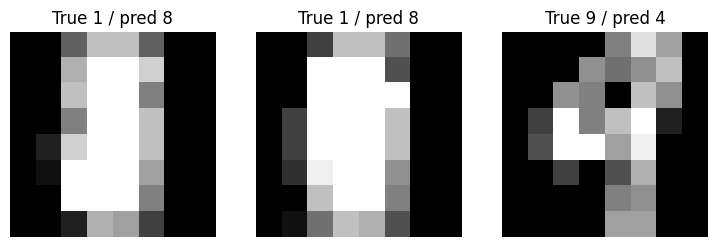

In [ ]:
# ------------------------------------------------------------
# CELL 9: Baseline, accuracy, macro F1, confusion matrices on TEST set.
# ------------------------------------------------------------
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, ConfusionMatrixDisplay
from collections import Counter
import matplotlib.pyplot as plt

def predict_all(model, loader):
    model.eval()
    preds = []
    with torch.no_grad():
        for xb, _ in loader:
            preds.append(model(xb.to(device)).argmax(dim=1).cpu())
    return torch.cat(preds).numpy()

# Majority-class baseline.
most_common = Counter(ytr.tolist()).most_common(1)[0][0]
baseline_preds = np.full_like(y_te, most_common)
baseline_acc   = accuracy_score(y_te, baseline_preds)

# Predictions on test set.
cnn_preds = predict_all(cnn, test_loader)
vit_preds = predict_all(vit, test_loader)

# Metrics table.
print(f"{'Model':<6} {'Accuracy':>10} {'MacroF1':>10}")
print("-" * 28)
print(f"{'Base':<6} {baseline_acc:>10.4f} {'—':>10}")
for name, p in [("CNN", cnn_preds), ("ViT", vit_preds)]:
    acc = accuracy_score(y_te, p)
    f1  = f1_score(y_te, p, average="macro")
    print(f"{name:<6} {acc:>10.4f} {f1:>10.4f}")

# Confusion matrices side by side.
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, name, p in [(axes[0], "CNN", cnn_preds), (axes[1], "ViT", vit_preds)]:
    cm = confusion_matrix(y_te, p, labels=range(10))
    ConfusionMatrixDisplay(cm, display_labels=range(10)).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(f"{name} confusion matrix")
plt.tight_layout(); plt.show()

# Show 3 CNN errors.
wrong = np.where(cnn_preds != y_te)[0][:3]
if len(wrong):
    fig, axes = plt.subplots(1, len(wrong), figsize=(3*len(wrong), 3))
    for ax, i in zip(np.atleast_1d(axes), wrong):
        ax.imshow(X_te[i], cmap="gray")
        ax.set_title(f"True {y_te[i]} / pred {cnn_preds[i]}")
        ax.axis("off")
    plt.show()

In [ ]:
# ------------------------------------------------------------
# CELL 10: Save checkpoints and JSON metadata, then download.
# ------------------------------------------------------------
import json, os

torch.save(cnn.state_dict(), "cnn_digit.pt")
torch.save(vit.state_dict(), "vit_digit.pt")

meta = {
    "pixel_divisor_train": 16,        # How training pixels were scaled.
    "pixel_divisor_upload": 255,      # How uploads are scaled in the app.
    "classes": list(range(10)),       # Class mapping 0-9.
    "image_size": [8, 8],             # Expected size.
    "embed_dim": 32, "vit_layers": 2, "vit_heads": 4,   # ViT constructor args.
}
with open("preprocess_meta.json", "w") as f:
    json.dump(meta, f, indent=2)

print("Saved:", [p for p in ("cnn_digit.pt","vit_digit.pt","preprocess_meta.json") if os.path.exists(p)])

# ---- Download to your machine (Colab only). ----
try:
    from google.colab import files
    for fname in ("cnn_digit.pt", "vit_digit.pt", "preprocess_meta.json"):
        files.download(fname)
except ImportError:
    print("Not running in Colab — files already in the working directory.")

Saved: ['cnn_digit.pt', 'vit_digit.pt', 'preprocess_meta.json']


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# Quick accuracy check across all 150 test images (uses app's exact pipeline).
import glob
from PIL import Image

hits_cnn = hits_vit = total = 0
for path in sorted(glob.glob("test_images/digit_*_*.png")):
    true_label = int(path.split("digit_")[1].split("_")[0])       # From filename.
    x, _       = prepare_upload(Image.open(path))                 # Same function the app uses.
    with torch.no_grad():
        c = int(cnn(x.to(device)).argmax())
        v = int(vit(x.to(device)).argmax())
    hits_cnn += (c == true_label)
    hits_vit += (v == true_label)
    total    += 1

print(f"CNN on {total} test images: {hits_cnn/total:.1%} correct")
print(f"ViT on {total} test images: {hits_vit/total:.1%} correct")

CNN on 150 test images: 42.0% correct
ViT on 150 test images: 40.7% correct


In [ ]:
# ------------------------------------------------------------
# CELL 11: prepare_upload pipeline — test it on a real digit and save a sample.
# ------------------------------------------------------------
import io
from PIL import Image, ImageDraw

def prepare_upload(pil_img, threshold=10):
    """
    open -> grayscale -> invert bright bg -> crop strokes -> center ->
    resize 8x8 -> divide by 255 -> float32 tensor [1,1,8,8].
    Returns (tensor, preview_array_0_to_1).
    """
    if pil_img is None:
        raise ValueError("No file uploaded.")

    img = pil_img.convert("L")                              # Grayscale.
    arr = np.asarray(img, dtype=np.uint8)                   # Array view.

    # Invert if background is bright (strokes must be bright for the model).
    if arr.mean() > 127:
        img = Image.fromarray(255 - arr)
        arr = np.asarray(img, dtype=np.uint8)

    # Crop to strokes above threshold.
    ys, xs = np.where(arr > threshold)
    if len(xs) == 0:
        raise ValueError("Blank image (no strokes).")
    crop = arr[ys.min():ys.max()+1, xs.min():xs.max()+1]

    # Center on square black canvas to keep aspect ratio.
    h, w = crop.shape
    side = max(h, w)
    canvas = np.zeros((side, side), dtype=np.uint8)
    canvas[(side-h)//2:(side-h)//2+h, (side-w)//2:(side-w)//2+w] = crop

    # Resize down to 8x8.
    small = Image.fromarray(canvas).resize((8, 8), Image.LANCZOS)
    arr8  = np.asarray(small, dtype=np.float32) / 255.0     # 0-255 -> 0-1.

    # CNN input shape [1,1,8,8].
    return torch.from_numpy(arr8).unsqueeze(0).unsqueeze(0), arr8

# --- Build a test image with a real sklearn digit, scaled up to 280x280 ---
digit_index = 0
digit_8x8   = (X_images[digit_index] * 16).astype(np.uint8)     # Back to 0-16.
big = Image.fromarray(digit_8x8).resize((280, 280), Image.NEAREST)
big.save("sample_for_app.png")                                  # Reuse in Streamlit test.
print("True label:", y_labels[digit_index])

# Run the pipeline on the saved photo.
tensor, preview = prepare_upload(Image.open("sample_for_app.png"))
print("Tensor shape:", tensor.shape)                            # [1,1,8,8].
print("Preview range:", preview.min(), "->", preview.max())

# Sanity: both models should predict the same digit on this prepared input.
with torch.no_grad():
    print("CNN predicts:", int(cnn(tensor.to(device)).argmax()))
    print("ViT predicts:", int(vit(tensor.to(device)).argmax()))

# Blank image is correctly rejected?
try:
    blank = Image.new("L", (100, 100), color=0)
    prepare_upload(blank)
    print("ERROR: blank should have been rejected!")
except ValueError as e:
    print("Blank rejected correctly:", e)

try:
    from google.colab import files
    files.download("sample_for_app.png")
except ImportError:
    pass

True label: 0
Tensor shape: torch.Size([1, 1, 8, 8])
Preview range: 0.0 -> 0.05490196
CNN predicts: 3
ViT predicts: 7
Blank rejected correctly: Blank image (no strokes).


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# ============================================================
# app.py — Streamlit digit recognizer with CNN + ViT.
# Run:  streamlit run app.py
# ============================================================
'''import io, json
import numpy as np
import torch
from torch import nn
from PIL import Image
import streamlit as st

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# ---------- Rebuild the exact model architectures (must match training) ----------
class DigitCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(1, 16, 3, padding=1)
        self.conv2 = nn.Conv2d(16, 32, 3, padding=1)
        self.act   = nn.ReLU()
        self.pool  = nn.MaxPool2d(2)
        self.fc1   = nn.Linear(32*2*2, 64)
        self.fc2   = nn.Linear(64, 10)
    def forward(self, x):
        x = self.act(self.conv1(x)); x = self.pool(x)
        x = self.act(self.conv2(x)); x = self.pool(x)
        x = x.flatten(1)
        x = self.act(self.fc1(x))
        return self.fc2(x)

def patchify(x):
    p = x.view(-1, 1, 4, 2, 4, 2)
    p = p.permute(0, 1, 2, 4, 3, 5)
    return p.reshape(-1, 16, 4)

class DigitViT(nn.Module):
    def __init__(self, embed_dim=32, n_heads=4, n_layers=2, dropout=0.1):
        super().__init__()
        self.patch_proj = nn.Linear(4, embed_dim)
        self.pos_embed  = nn.Parameter(torch.zeros(1, 16, embed_dim))
        enc = nn.TransformerEncoderLayer(
            d_model=embed_dim, nhead=n_heads,
            dim_feedforward=64, dropout=dropout, batch_first=True)
        self.encoder = nn.TransformerEncoder(enc, num_layers=n_layers)
        self.norm    = nn.LayerNorm(embed_dim)
        self.head    = nn.Linear(embed_dim, 10)
    def forward(self, x):
        t = self.patch_proj(patchify(x)) + self.pos_embed
        t = self.encoder(t)
        t = self.norm(t)
        return self.head(t.mean(dim=1))

# ---------- Load checkpoints once (cached) ----------
@st.cache_resource
def load_models():
    cnn = DigitCNN().to(device)
    cnn.load_state_dict(torch.load("cnn_digit.pt", map_location=device))
    cnn.eval()

    vit = DigitViT().to(device)
    vit.load_state_dict(torch.load("vit_digit.pt", map_location=device))
    vit.eval()

    with open("preprocess_meta.json") as f:
        meta = json.load(f)
    return cnn, vit, meta

# ---------- Upload pipeline (same as Cell 11) ----------
def prepare_upload(pil_img, threshold=10):
    if pil_img is None:
        raise ValueError("No file uploaded.")
    img = pil_img.convert("L")
    arr = np.asarray(img, dtype=np.uint8)
    if arr.mean() > 127:                                # Invert if bg is bright.
        img = Image.fromarray(255 - arr)
        arr = np.asarray(img, dtype=np.uint8)
    ys, xs = np.where(arr > threshold)
    if len(xs) == 0:
        raise ValueError("Blank image (no strokes).")
    crop = arr[ys.min():ys.max()+1, xs.min():xs.max()+1]
    h, w = crop.shape
    side = max(h, w)
    canvas = np.zeros((side, side), dtype=np.uint8)
    canvas[(side-h)//2:(side-h)//2+h, (side-w)//2:(side-w)//2+w] = crop
    small = Image.fromarray(canvas).resize((8, 8), Image.LANCZOS)
    arr8  = np.asarray(small, dtype=np.float32) / 255.0
    return torch.from_numpy(arr8).unsqueeze(0).unsqueeze(0), arr8

# ---------- UI ----------
st.set_page_config(page_title="Digit Recognizer", layout="centered")
st.title("Handwritten Digit Recognition")
st.caption("CNN and Vision Transformer side by side. Upload one clear handwritten digit.")

try:
    cnn, vit, meta = load_models()
except FileNotFoundError as e:
    st.error(f"Missing checkpoint: {e}. Put cnn_digit.pt, vit_digit.pt, "
             "preprocess_meta.json next to app.py.")
    st.stop()

upload = st.file_uploader("Upload a PNG/JPEG containing one digit",
                          type=["png", "jpg", "jpeg"])

if upload is None:
    st.info("Waiting for an image…")                    # Reject missing gracefully.

else:
    try:
        pil = Image.open(io.BytesIO(upload.read()))
        pil.load()
    except Exception:
        st.error("This file could not be opened as an image.")  # Reject broken file.
        st.stop()

    col1, col2 = st.columns(2)
    with col1:
        st.subheader("Your upload")
        st.image(pil, width=200)

    try:
        x_tensor, preview = prepare_upload(pil)
    except ValueError as e:
        st.warning(f"Rejected: {e}")                    # Reject blank gracefully.
        st.stop()

    with col2:
        st.subheader("Prepared 8x8 input")
        preview_img = Image.fromarray((preview * 255).astype(np.uint8))
        st.image(preview_img.resize((160, 160), Image.NEAREST), width=160)

    # Both models predict in eval/no_grad mode.
    x_tensor = x_tensor.to(device)
    with torch.no_grad():
        cnn_logits = cnn(x_tensor)
        vit_logits = vit(x_tensor)
        cnn_pred   = int(cnn_logits.argmax(dim=1).item())
        vit_pred   = int(vit_logits.argmax(dim=1).item())

    st.markdown("### Predictions")
    p1, p2 = st.columns(2)
    p1.metric("CNN", str(cnn_pred))
    p2.metric("Vision Transformer", str(vit_pred))

    if cnn_pred == vit_pred:
        st.success(f"Both models agree: digit **{cnn_pred}**.")
    else:
        st.warning(f"Models disagree: CNN {cnn_pred}, ViT {vit_pred}.")

    with st.expander("Class probabilities"):
        cn = torch.softmax(cnn_logits, dim=1)[0].cpu().numpy()
        vt = torch.softmax(vit_logits, dim=1)[0].cpu().numpy()
        st.write("**CNN**"); st.bar_chart({str(i): float(cn[i]) for i in range(10)})
        st.write("**ViT**"); st.bar_chart({str(i): float(vt[i]) for i in range(10)})
        '''

'import io, json\nimport numpy as np\nimport torch\nfrom torch import nn\nfrom PIL import Image\nimport streamlit as st\n\ndevice = torch.device("cuda" if torch.cuda.is_available() else "cpu")\n\n# ---------- Rebuild the exact model architectures (must match training) ----------\nclass DigitCNN(nn.Module):\n    def __init__(self):\n        super().__init__()\n        self.conv1 = nn.Conv2d(1, 16, 3, padding=1)\n        self.conv2 = nn.Conv2d(16, 32, 3, padding=1)\n        self.act   = nn.ReLU()\n        self.pool  = nn.MaxPool2d(2)\n        self.fc1   = nn.Linear(32*2*2, 64)\n        self.fc2   = nn.Linear(64, 10)\n    def forward(self, x):\n        x = self.act(self.conv1(x)); x = self.pool(x)\n        x = self.act(self.conv2(x)); x = self.pool(x)\n        x = x.flatten(1)\n        x = self.act(self.fc1(x))\n        return self.fc2(x)\n\ndef patchify(x):\n    p = x.view(-1, 1, 4, 2, 4, 2)\n    p = p.permute(0, 1, 2, 4, 3, 5)\n    return p.reshape(-1, 16, 4)\n\nclass DigitViT(nn.Module

# **see the data set**




In [ ]:
# ------------------------------------------------------------
# SEE THE DATASET
# ------------------------------------------------------------
from sklearn.datasets import load_digits
import numpy as np

digits = load_digits()

# The Bunch object has three important fields.
print("Keys:", digits.keys())
# -> dict_keys(['data','target','frame','feature_names','target_names',
#               'images','DESCR'])

# 1) Labels — one integer 0-9 per image.
print("\nFirst 20 labels:", digits.target[:20])
# -> [0 1 2 3 4 5 6 7 8 9 0 1 2 3 4 5 6 7 8 9]

# 2) Flattened view — each image is 64 numbers.
print("\nData shape :", digits.data.shape)      # (1797, 64)

# 3) Image view — same data as 8x8 grids.
print("Images shape:", digits.images.shape)     # (1797, 8, 8)

# 4) Raw pixel values (0-16).
print("\nFirst image (raw 0-16):")
print(digits.images[0].astype(int))
# -> a 8x8 grid of integers

# 5) After normalization for training (what the project uses).
print("\nFirst image divided by 16 (0-1):")
print((digits.images[0] / 16.0).round(2))

# 6) Class balance.
import numpy as np
print("\nSamples per digit:", np.bincount(digits.target))

# 7) Peek at a few image values with the label next to them.
for i in [0, 100, 500, 1500]:
    print(f"\nSample {i}: label = {digits.target[i]}")
    print(digits.images[i].astype(int))

Keys: dict_keys(['data', 'target', 'frame', 'feature_names', 'target_names', 'images', 'DESCR'])

First 20 labels: [0 1 2 3 4 5 6 7 8 9 0 1 2 3 4 5 6 7 8 9]

Data shape : (1797, 64)
Images shape: (1797, 8, 8)

First image (raw 0-16):
[[ 0  0  5 13  9  1  0  0]
 [ 0  0 13 15 10 15  5  0]
 [ 0  3 15  2  0 11  8  0]
 [ 0  4 12  0  0  8  8  0]
 [ 0  5  8  0  0  9  8  0]
 [ 0  4 11  0  1 12  7  0]
 [ 0  2 14  5 10 12  0  0]
 [ 0  0  6 13 10  0  0  0]]

First image divided by 16 (0-1):
[[0.   0.   0.31 0.81 0.56 0.06 0.   0.  ]
 [0.   0.   0.81 0.94 0.62 0.94 0.31 0.  ]
 [0.   0.19 0.94 0.12 0.   0.69 0.5  0.  ]
 [0.   0.25 0.75 0.   0.   0.5  0.5  0.  ]
 [0.   0.31 0.5  0.   0.   0.56 0.5  0.  ]
 [0.   0.25 0.69 0.   0.06 0.75 0.44 0.  ]
 [0.   0.12 0.88 0.31 0.62 0.75 0.   0.  ]
 [0.   0.   0.38 0.81 0.62 0.   0.   0.  ]]

Samples per digit: [178 182 177 183 181 182 181 179 174 180]

Sample 0: label = 0
[[ 0  0  5 13  9  1  0  0]
 [ 0  0 13 15 10 15  5  0]
 [ 0  3 15  2  0 11  8  0]
 [ 0  

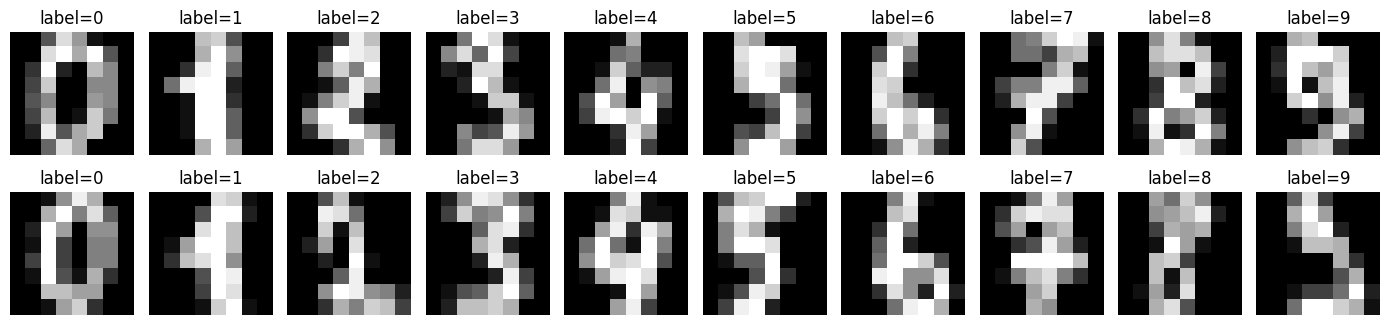

In [ ]:
# ------------------------------------------------------------
# SHOW 20 DIGITS AS A GRID (this is the "dataset" you're training on)
# ------------------------------------------------------------
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits

digits = load_digits()

fig, axes = plt.subplots(2, 10, figsize=(14, 3.5))
for ax, img, label in zip(axes.flat, digits.images[:20], digits.target[:20]):
    ax.imshow(img, cmap="gray")                 # 8x8 pixel grid.
    ax.set_title(f"label={label}")
    ax.axis("off")
plt.tight_layout()
plt.show()